# NB 04 · Scénario 3 : Graphe de relations

**Situation :** l'inventaire du NB 02 dit *qui* est présent sur le théâtre GOLFE. L'état-major demande maintenant **qui est lié à qui** :
- Quels **sous-théâtres** se dessinent ?
- Quels acteurs servent de **pivots** entre eux ?
- Existe-t-il un **lien caché** entre deux acteurs qu'on ne voit jamais ensemble ?

**Le principe :** deux entités citées **dans la même phrase** sont reliées. Plus elles le sont souvent, plus le lien est épais. La phrase est la bonne unité : deux noms dans le même article peuvent n'avoir aucun rapport, deux noms dans la même phrase en ont presque toujours un.

| Notion | En clair | Question du renseignement |
|---|---|---|
| **Nœud** | une entité (personne, force, site…) | qui est présent ? |
| **Arête** | une co-citation dans une phrase | qui est lié à qui ? |
| **Communauté** | un groupe d'entités très liées entre elles | quels sous-théâtres ? |
| **Intermédiarité** | combien de « plus courts chemins » passent par un nœud | qui fait le pont ? |
| **Chemin** | une suite de liens entre deux nœuds | lien caché ? |

> **Règle d'or :** une co-citation n'est **pas** une preuve de collusion. C'est une **piste**. Chaque lien affiché ici est donc **sourcé** : Spirit Digger retrouve la phrase exacte qui le justifie.

In [1]:
import sys
from pathlib import Path

# On retrouve la racine du projet (le dossier qui contient data_lake/) pour importer src/
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_lake").is_dir())
sys.path.insert(0, str(RACINE / "src"))

import itertools
import math
from collections import Counter, defaultdict
from html import escape

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import spacy
from IPython.display import HTML, display
from pyvis.network import Network

from spirit_digger.config import OUTPUTS
from spirit_digger.lexique_militaire import ajouter_lexique
from spirit_digger.style import ACCENT, ALERTE, FOND, OK, PALETTE, TEXTE, VEILLE, bandeau, theme_ops

theme_ops()
pd.set_option("display.max_colwidth", 120)
bandeau("NB 04 · Graphe de relations", "Théâtre GOLFE : sous-théâtres, pivots et liens cachés.")

ent = pd.read_parquet(OUTPUTS / "entites_golfe.parquet")
corpus = pd.read_parquet(OUTPUTS / "corpus_golfe.parquet").set_index("doc_id")
CATEGORIE = ent.groupby("entite")["categorie"].agg(lambda s: s.value_counts().index[0])
print(f"{len(ent):,} mentions · {ent['entite'].nunique():,} entités · {ent['doc_id'].nunique():,} articles")

82,192 mentions · 10,986 entités · 2,196 articles


## 1. Construction du graphe

Deux filtres, pour ne garder que du solide :
- une entité doit apparaître dans **au moins 8 articles** (sinon c'est anecdotique) ;
- un lien doit être attesté dans **au moins 3 articles différents** : une seule source, ce peut être l'erreur d'un journaliste.

In [2]:
MIN_ARTICLES_NOEUD = 8
MIN_ARTICLES_LIEN = 3

articles_par_entite = ent.groupby("entite")["doc_id"].nunique()
retenues = articles_par_entite[articles_par_entite >= MIN_ARTICLES_NOEUD].index
phrases = (ent[ent["entite"].isin(retenues)]
             .drop_duplicates(["doc_id", "phrase", "entite"])
             .groupby(["doc_id", "phrase"])["entite"].agg(sorted))

nb_phrases = Counter()
articles_lien = defaultdict(set)
for (doc_id, _), entites in phrases.items():
    for a, b in itertools.combinations(entites, 2):
        nb_phrases[(a, b)] += 1
        articles_lien[(a, b)].add(doc_id)

# PMI : combien de fois plus souvent ensemble que si le hasard seul les réunissait (en log)
freq = Counter(e for entites in phrases for e in entites)
N_PHRASES = len(phrases)

G = nx.Graph()
for (a, b), n in nb_phrases.items():
    if len(articles_lien[(a, b)]) >= MIN_ARTICLES_LIEN:
        G.add_edge(a, b, weight=n, articles=len(articles_lien[(a, b)]),
                   pmi=math.log(n * N_PHRASES / (freq[a] * freq[b])))
for n in G:
    G.nodes[n].update(categorie=CATEGORIE[n], articles=int(articles_par_entite[n]))
print(f"Graphe : {G.number_of_nodes()} nœuds · {G.number_of_edges():,} liens")

Graphe : 441 nœuds · 2,229 liens


## 2. Les sous-théâtres : détection de communautés

L'algorithme de **Louvain** regroupe les nœuds qui ont beaucoup plus de liens entre eux qu'avec le reste. On ne lui dit pas combien de groupes chercher.

**Tri : l'automate propose, l'analyste dispose.** Le corpus contient aussi des pages « fourre-tout » (directs, sport, tech). Une communauté est gardée si :
- elle compte **au moins 3 membres**, et
- elle contient **au moins une entité militaire**, ou bien au moins **25 % de ses membres** sont directement liés à une entité militaire.

La règle laisse passer un cas limite : la Coupe du monde 2026, où joue l'équipe d'Iran. L'analyste l'écarte **à la main**, avec une justification écrite. C'est la bonne pratique : chaque décision humaine est tracée.

In [3]:
MILITAIRE = {"FORCE_ARMEE", "SITE_STRATEGIQUE", "ARMEMENT", "OPERATION", "NAVIRE"}
communautes = nx.community.louvain_communities(G, weight="weight", resolution=1.2, seed=7)


ECARTS_MANUELS = {"Fifa": "Coupe du monde 2026 : sujet sportif, pas sécuritaire"}   # un membre → raison


def ancre_au_theatre(n):
    return G.nodes[n]["categorie"] in MILITAIRE or any(G.nodes[v]["categorie"] in MILITAIRE for v in G[n])


def nommer(membres, k=4):
    """Nom d'une communauté : ses membres les plus connectés, hors grands pays-carrefours."""
    tries = sorted(membres, key=lambda n: -G.degree(n, weight="weight"))
    hors_lieux = [n for n in tries if G.nodes[n]["categorie"] != "LIEU"]
    return " · ".join((hors_lieux or tries)[:k])


tableau, garder = [], set()
for c in sorted(communautes, key=len, reverse=True):
    pertinence = np.mean([ancre_au_theatre(n) for n in c])
    militaires = sum(G.nodes[n]["categorie"] in MILITAIRE for n in c)
    manuel = [raison for membre, raison in ECARTS_MANUELS.items() if membre in c]
    if manuel:
        statut = "écarté (analyste) : " + manuel[0]
    elif len(c) >= 3 and (militaires > 0 or pertinence >= 0.25):
        statut = "THÉÂTRE"
    else:
        statut = "hors théâtre"
    if statut == "THÉÂTRE":
        garder |= c
    tableau.append({"membres": len(c), "entités militaires": militaires, "ancrage": pertinence, "statut": statut, "noyau": nommer(c),
                    "exemples de membres": ", ".join(sorted(c, key=lambda n: -G.nodes[n]["articles"])[:8])})
tableau = pd.DataFrame(tableau)

T = G.subgraph(garder).copy()                     # le graphe du théâtre, sans le bruit
comms = [c for c in communautes if c <= garder]
comms.sort(key=len, reverse=True)
COMM = {n: i for i, c in enumerate(comms) for n in c}
NOM_COMM = {i: nommer(c, 3) for i, c in enumerate(comms)}
nx.set_node_attributes(T, COMM, "communaute")

print(f"{len(comms)} sous-théâtres retenus · {T.number_of_nodes()} nœuds · "
      f"{len(communautes) - len(comms)} communautés écartées")
(tableau.style.format({"ancrage": "{:.0%}"})
   .map(lambda v: f"color:{OK if v == 'THÉÂTRE' else VEILLE if 'analyste' in v else ALERTE};font-weight:bold",
        subset=["statut"])
   .hide(axis="index"))

8 sous-théâtres retenus · 386 nœuds · 10 communautés écartées


membres,entités militaires,ancrage,statut,noyau,exemples de membres
139,13,34%,THÉÂTRE,Donald Trump · Strait of Hormuz · IRGC · Ali Khamenei,"Iran, United States, Donald Trump, Strait of Hormuz, IRGC, White House, Ali Khamenei, Truth Social"
91,0,37%,THÉÂTRE,United Nations · European Union · Vladimir Putin · Xi Jinping,"United Kingdom, China, Russia, Germany, United Nations, Europe, Ukraine, France"
48,8,54%,THÉÂTRE,Hezbollah · Benjamin Netanyahu · ballistic missile · Hamas,"Israel, Lebanon, Hezbollah, Benjamin Netanyahu, ballistic missile, Gaza, Beirut, Syria"
46,1,41%,THÉÂTRE,Marco Rubio · Abbas Araghchi · JD Vance · Esmaeil Baghaei,"Pakistan, India, Abbas Araghchi, Marco Rubio, Islamabad, JD Vance, Esmaeil Baghaei, Shehbaz Sharif"
28,6,79%,THÉÂTRE,drone · US Navy · cruise missile · Fujairah,"drone, Gulf, United Arab Emirates, Qatar, Saudi Arabia, Iraq, Kuwait, Turkey"
20,10,100%,THÉÂTRE,CENTCOM · tanker · oil tanker · Gulf of Oman,"CENTCOM, Oman, tanker, oil tanker, Gulf of Oman, warship, Indian Ocean, Palau"
16,0,25%,"écarté (analyste) : Coupe du monde 2026 : sujet sportif, pas sécuritaire",Fifa · Gianni Infantino · FIFA · FFIRI,"Canada, Egypt, Mexico, Fifa, Belgium, Los Angeles, New Zealand, Seattle"
10,0,20%,hors théâtre,Yvette Cooper · Countries,"Middle East, United States of America, Baghdad, Tijuana, Arizona, Yvette Cooper, Southeast Asia, Countries"
9,5,78%,THÉÂTRE,IAEA · Natanz · Isfahan · Fordow,"IAEA, Natanz, Isfahan, Fordow, Vienna, Rafael Grossi, Tomahawk, bunker buster"
8,0,0%,hors théâtre,NBA · Knicks · New York Knicks,"New York, Texas, NBA, Knicks, New York Knicks, San Antonio Spurs, Madison Square Garden, Manhattan"


## 3. Les pivots : qui fait le pont entre les sous-théâtres ?

**L'intermédiarité** (*betweenness*) mesure combien de plus courts chemins entre deux nœuds passent par un acteur. Un acteur très intermédiaire **contrôle la circulation** entre des groupes qui, sans lui, seraient peu reliés.

On écarte les pays de ce classement : « Iran » ou « United States » sont évidemment au centre de tout. On cherche les **personnes, forces et organisations** qui jouent ce rôle de pont.

In [4]:
intermediarite = nx.betweenness_centrality(T)
pivots = pd.DataFrame([{
    "acteur": n, "catégorie": T.nodes[n]["categorie"], "articles": T.nodes[n]["articles"],
    "liens": T.degree(n), "intermédiarité": intermediarite[n],
    "sous-théâtres reliés": len({COMM[v] for v in T[n]} - {COMM[n]}) + 1,
    "son sous-théâtre": NOM_COMM[COMM[n]],
} for n in T if T.nodes[n]["categorie"] != "LIEU"])
pivots = pivots.sort_values("intermédiarité", ascending=False).head(12)
pivots.style.format({"intermédiarité": "{:.3f}"}).bar(subset=["intermédiarité"], color=ACCENT).hide(axis="index")

acteur,catégorie,articles,liens,intermédiarité,sous-théâtres reliés,son sous-théâtre
Donald Trump,PERSONNE,1035,140,0.072,8,Donald Trump · Strait of Hormuz · IRGC
Strait of Hormuz,SITE_STRATEGIQUE,762,101,0.040,7,Donald Trump · Strait of Hormuz · IRGC
drone,ARMEMENT,308,62,0.020,6,drone · US Navy · cruise missile
European Union,ORGANISATION,105,22,0.013,4,United Nations · European Union · Vladimir Putin
IRGC,FORCE_ARMEE,257,43,0.005,7,Donald Trump · Strait of Hormuz · IRGC
Nabatieh,ORGANISATION,13,5,0.005,1,Hezbollah · Benjamin Netanyahu · ballistic missile
Hezbollah,FORCE_ARMEE,238,27,0.004,4,Hezbollah · Benjamin Netanyahu · ballistic missile
CENTCOM,FORCE_ARMEE,154,29,0.003,5,CENTCOM · tanker · oil tanker
Ali Khamenei,PERSONNE,192,26,0.003,5,Donald Trump · Strait of Hormuz · IRGC
Benjamin Netanyahu,PERSONNE,213,28,0.002,5,Hezbollah · Benjamin Netanyahu · ballistic missile


## 4. Lien fréquent ≠ lien fort

Le lien le plus **fréquent** est presque toujours trivial : « Iran – United States » est cité des milliers de fois. Le lien le plus **spécifique** dit beaucoup plus : deux entités qui apparaissent *presque toujours ensemble*, bien plus que le hasard ne le voudrait. On le mesure avec la **PMI** (*Pointwise Mutual Information*, information mutuelle ponctuelle).

In [5]:
liens = nx.to_pandas_edgelist(T, source="a", target="b")
liens = liens[~((liens["a"].map(CATEGORIE) == "LIEU") & (liens["b"].map(CATEGORIE) == "LIEU"))]   # pas de paires pays-pays
gros = articles_par_entite[articles_par_entite >= 15].index        # entités assez présentes pour être lues

frequents = liens.sort_values("weight", ascending=False).head(8)
specifiques = (liens[liens["a"].isin(gros) & liens["b"].isin(gros) & (liens["weight"] >= 5)]
                  .sort_values("pmi", ascending=False).head(8))

cote_a_cote = pd.concat([
    frequents.assign(lien=frequents["a"] + " — " + frequents["b"])[["lien", "weight"]]
             .rename(columns={"lien": "les plus FRÉQUENTS", "weight": "phrases"}).reset_index(drop=True),
    specifiques.assign(lien=specifiques["a"] + " — " + specifiques["b"])[["lien", "pmi"]]
               .rename(columns={"lien": "les plus SPÉCIFIQUES", "pmi": "PMI"}).reset_index(drop=True),
], axis=1)
cote_a_cote.style.format({"PMI": "{:.1f}"}).hide(axis="index")

les plus FRÉQUENTS,phrases,les plus SPÉCIFIQUES,PMI
Iran — Donald Trump,2109,Jared Kushner — Steve Witkoff,6.1
United States — Donald Trump,1476,Scott Bessent — Treasury,5.6
Iran — Strait of Hormuz,1106,Houthis — Yemen,5.5
United States — Strait of Hormuz,755,Esmaeil Baghaei — Iranian Foreign Ministry,5.3
Israel — Hezbollah,326,Fordow — Isfahan,5.3
Iran — Ali Khamenei,314,Natanz — Fordow,5.3
Donald Trump — Strait of Hormuz,307,Natanz — Isfahan,5.2
Hezbollah — Lebanon,306,Esmaeil Baghaei — foreign ministry,5.2


**Lecture :** à gauche, des évidences. À droite, de **vraies relations de travail** : un responsable et son institution, une arme et sa cible, un négociateur et son médiateur. Un PMI de 5 signifie que la paire apparaît environ e⁵ ≈ 150 fois plus souvent ensemble que par hasard.

## 5. Vue d'ensemble statique (pour les slides)

Le cœur du réseau : les 70 entités les plus citées. Chaque couleur correspond à un sous-théâtre.

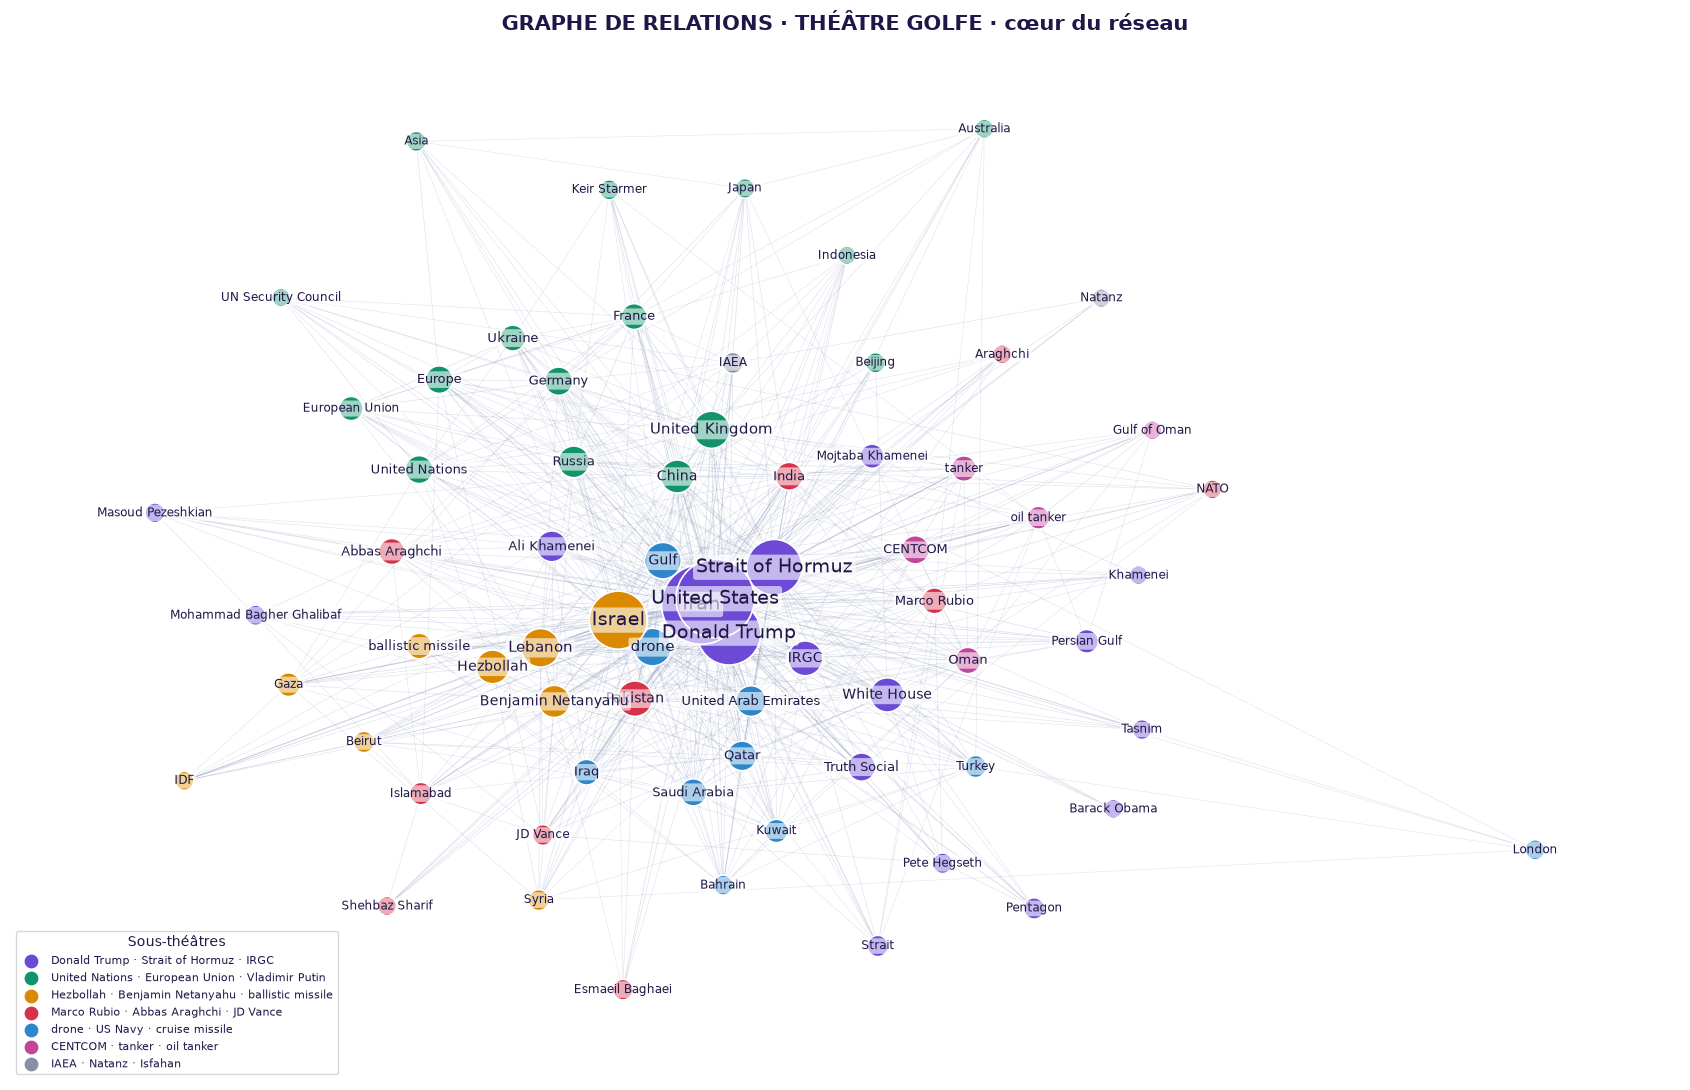

In [6]:
coeur = sorted(T, key=lambda n: -T.nodes[n]["articles"])[:70]
H = T.subgraph(coeur)
pos = nx.spring_layout(H, weight="weight", k=1.6 / math.sqrt(len(H)), iterations=200, seed=7)
COULEURS_COMM = PALETTE + ["#9be15d", "#f78fb3", "#c0a0ff", "#6ad5e8", "#e8b86a"]

fig, ax = plt.subplots(figsize=(17, 11))
poids = np.array([H[a][b]["weight"] for a, b in H.edges()])
nx.draw_networkx_edges(H, pos, ax=ax, width=0.3 + 2.5 * np.sqrt(poids / poids.max()), alpha=0.25, edge_color="#7f8bb3")
nx.draw_networkx_nodes(H, pos, ax=ax, node_size=[40 + 4 * H.nodes[n]["articles"] ** 0.9 for n in H],
                       node_color=[COULEURS_COMM[COMM[n] % len(COULEURS_COMM)] for n in H],
                       edgecolors=FOND, linewidths=1.2)
for n, (x, y) in pos.items():
    ax.text(x, y, n, fontsize=8 + min(H.nodes[n]["articles"] / 120, 6), ha="center", va="center", color=TEXTE,
            bbox=dict(boxstyle="round,pad=0.15", fc=FOND, ec="none", alpha=0.6))
for i in sorted({COMM[n] for n in H}):
    ax.scatter([], [], color=COULEURS_COMM[i % len(COULEURS_COMM)], s=80, label=NOM_COMM[i])
ax.legend(loc="lower left", fontsize=8, title="Sous-théâtres", frameon=True)
ax.set_title("GRAPHE DE RELATIONS · THÉÂTRE GOLFE · cœur du réseau", fontsize=15)
ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUTS / "04_graphe_coeur.png", dpi=130)
plt.show()

## 5 bis. Vue arborescente : l'arbre des relations

Le graphe « en toile » montre tout, mais il est dense. Pour une diapo ou un briefing, on le réorganise en **arbre**, comme un organigramme :
- **la racine** est l'acteur le plus connecté du théâtre, celui qui concentre le plus de liens ;
- **les branches** mènent au **chef de file de chaque sous-théâtre**, c'est-à-dire sa personne, force armée ou organisation la plus citée ;
- **les feuilles** sont, pour chaque chef de file, **les acteurs auxquels il est le plus lié** dans son sous-théâtre.

Le chiffre sur chaque lien est le nombre de phrases où les deux acteurs sont cités ensemble. Un trait pointillé signale qu'il n'existe pas de co-citation directe : le chef de file est rattaché à la racine par son sous-théâtre, pas par une phrase.

Racine : Iran · 8 branches (une par sous-théâtre)


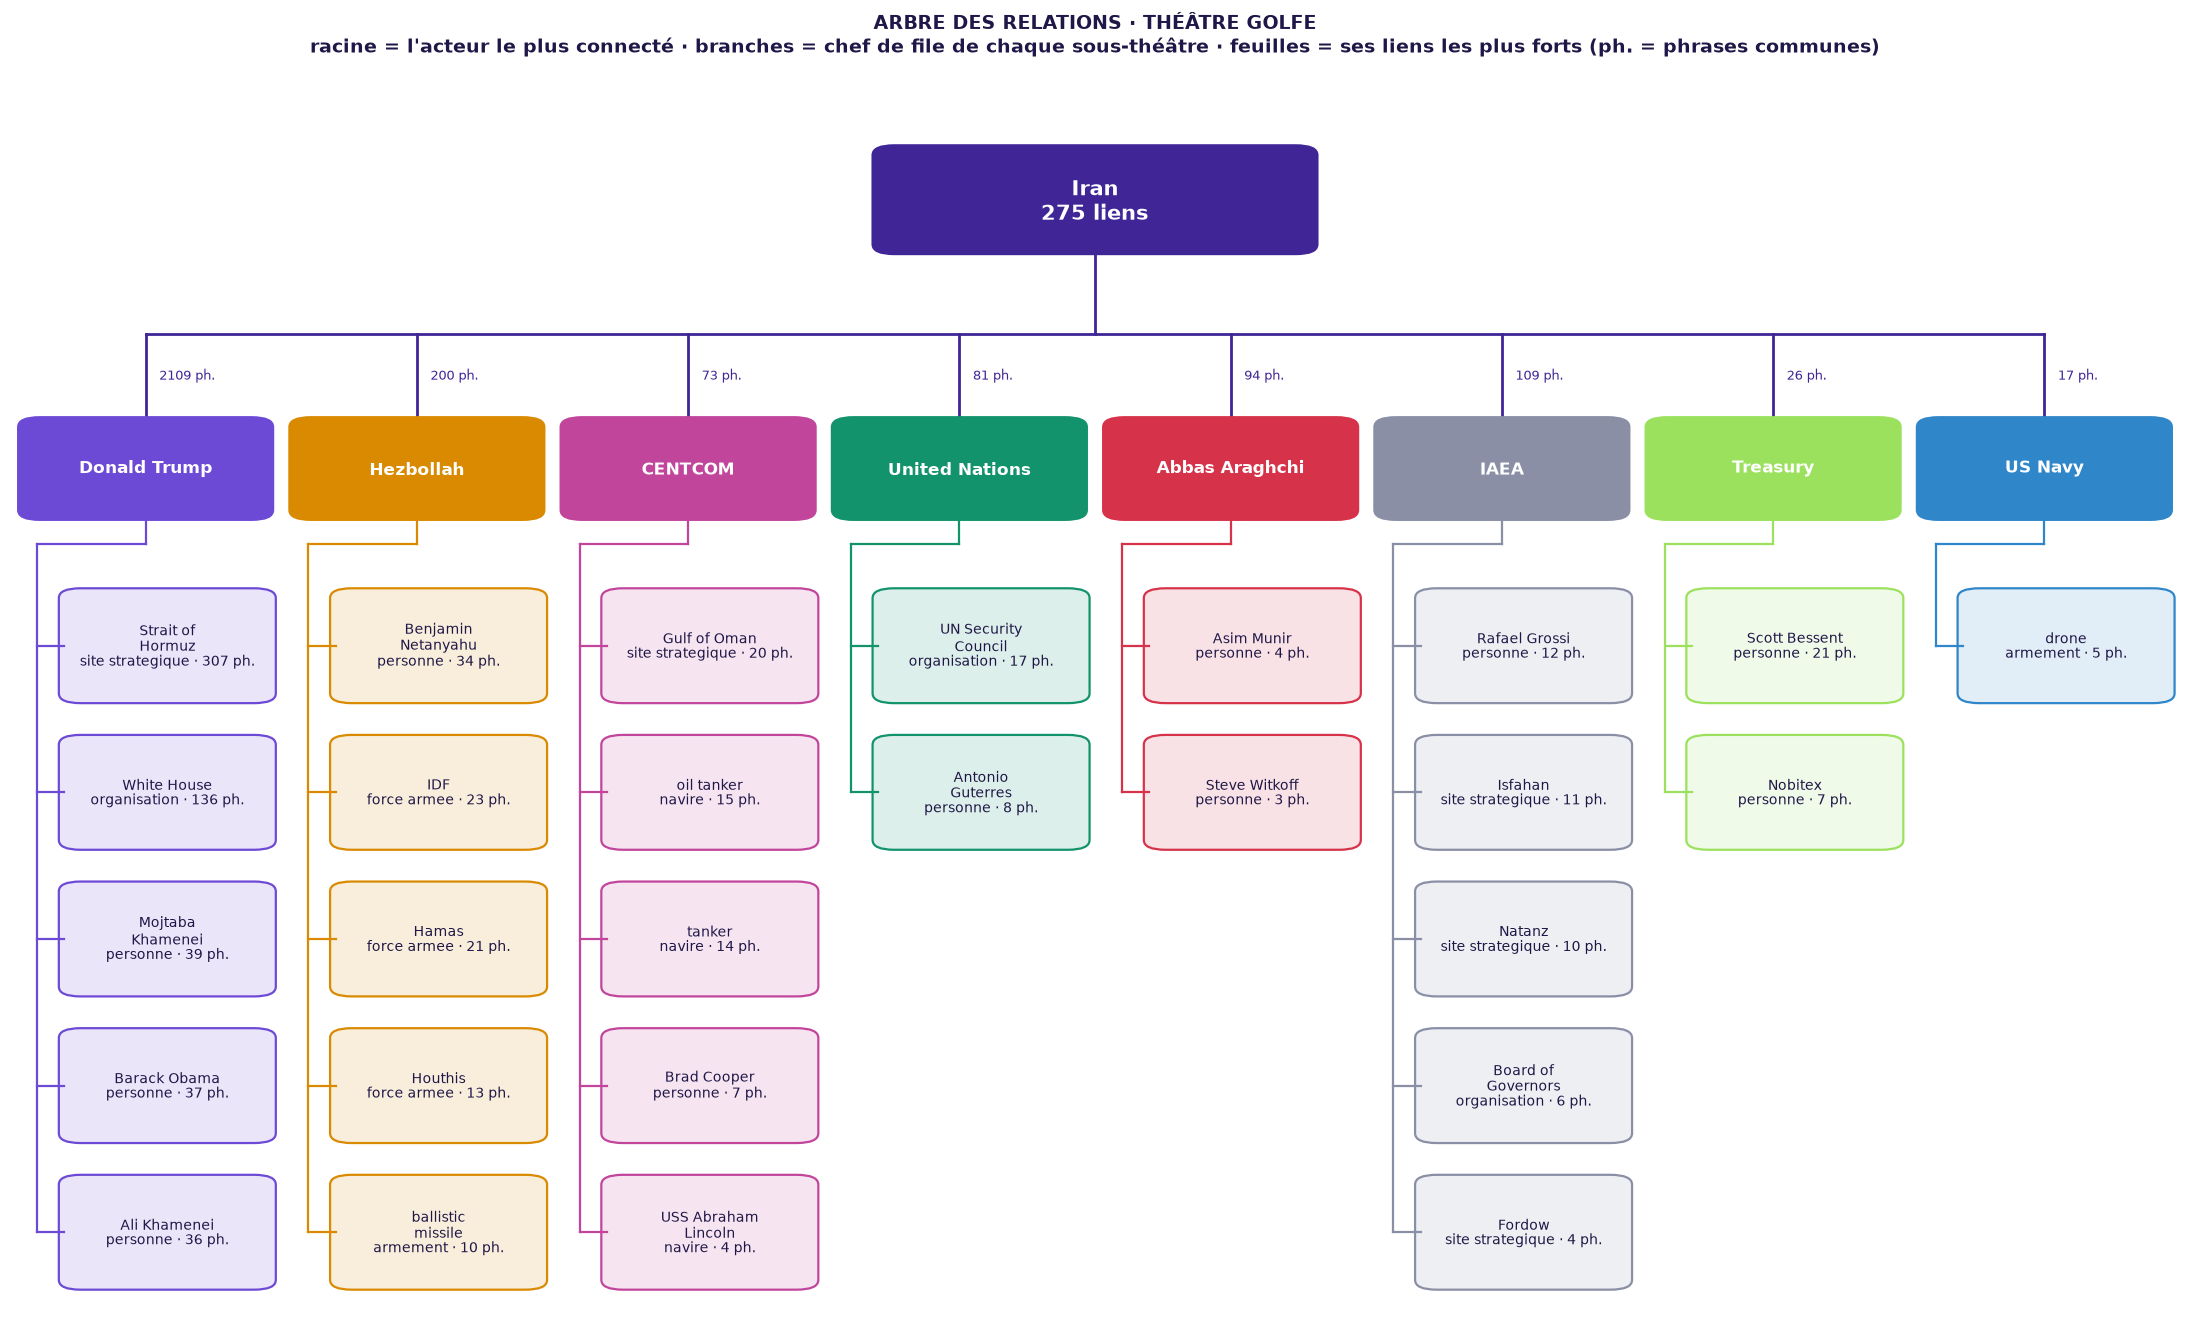

In [7]:
import textwrap
from matplotlib.colors import to_rgba
from matplotlib.patches import FancyBboxPatch

ENFANTS_PAR_BRANCHE = 5
RACINE_ARBRE = max(T, key=lambda n: T.degree(n, weight="weight"))   # l'acteur qui concentre le plus de liens

branches = []
for i, membres in enumerate(comms):
    candidats = [n for n in membres if n != RACINE_ARBRE and T.nodes[n]["categorie"] != "LIEU"]
    if len(candidats) < 2:
        continue
    acteurs_comm = [n for n in candidats if T.nodes[n]["categorie"] in {"PERSONNE", "FORCE_ARMEE", "ORGANISATION"}]
    chef = max(acteurs_comm or candidats, key=lambda n: T.nodes[n]["articles"])   # un acteur de préférence
    voisins = [v for v in T[chef] if v in membres and v != RACINE_ARBRE and T.nodes[v]["categorie"] != "LIEU"]
    enfants = sorted(voisins, key=lambda v: -T[chef][v]["weight"])[:ENFANTS_PAR_BRANCHE]
    branches.append({"comm": i, "chef": chef, "enfants": enfants})
branches.sort(key=lambda b: -T.nodes[b["chef"]]["articles"])
print(f"Racine : {RACINE_ARBRE} · {len(branches)} branches (une par sous-théâtre)")


def boite(ax, x, y, largeur, hauteur, texte, fond, bord, couleur_texte, taille, gras=False):
    ax.add_patch(FancyBboxPatch((x - largeur / 2, y - hauteur / 2), largeur, hauteur,
                                boxstyle="round,pad=0.02,rounding_size=0.08", facecolor=fond,
                                edgecolor=bord, linewidth=1.6, zorder=3))
    ax.text(x, y, texte, ha="center", va="center", fontsize=taille, color=couleur_texte,
            fontweight="bold" if gras else "normal", zorder=4, linespacing=1.15)


def poids(a, b):
    return T[a][b]["weight"] if T.has_edge(a, b) else None


n = len(branches)
Y_RACINE, Y_CHEF, Y_ENFANT0, PAS = 10.4, 8.2, 6.75, 1.2
fig, ax = plt.subplots(figsize=(2.75 * n, 13.5))
ax.set_xlim(0, n)
ax.set_ylim(Y_ENFANT0 - PAS * (ENFANTS_PAR_BRANCHE - 1) - 0.8, Y_RACINE + 1.0)
ax.axis("off")
ax.grid(False)

# Racine
x_racine = n / 2
boite(ax, x_racine, Y_RACINE, 1.6, 0.85, f"{RACINE_ARBRE}\n{T.degree(RACINE_ARBRE)} liens",
      "#3f2596", "#3f2596", "white", 15, gras=True)

y_bus = (Y_RACINE + Y_CHEF) / 2
ax.plot([x_racine, x_racine], [Y_RACINE - 0.43, y_bus], color="#3f2596", lw=2, zorder=1)
ax.plot([0.5, n - 0.5], [y_bus, y_bus], color="#3f2596", lw=2, zorder=1)

for k, b in enumerate(branches):
    xc = k + 0.5
    couleur = COULEURS_COMM[b["comm"] % len(COULEURS_COMM)]
    w = poids(RACINE_ARBRE, b["chef"])

    # lien racine -> chef de file
    ax.plot([xc, xc], [y_bus, Y_CHEF + 0.42], color="#3f2596", lw=2, zorder=1, ls="-" if w else (0, (4, 3)))
    ax.text(xc + 0.05, (y_bus + Y_CHEF + 0.42) / 2, f"{w} ph." if w else "", fontsize=9, color="#3f2596",
            ha="left", va="center")

    # chef de file
    boite(ax, xc, Y_CHEF, 0.9, 0.8, textwrap.fill(b["chef"], 14), couleur, couleur, "white", 12, gras=True)

    # feuilles : une colonne sous le chef, reliées par une « épine » verticale
    x_epine = xc - 0.4
    y_bas = Y_ENFANT0 - PAS * (len(b["enfants"]) - 1)
    if b["enfants"]:
        ax.plot([xc, xc], [Y_CHEF - 0.4, Y_CHEF - 0.62], color=couleur, lw=1.6, zorder=1)
        ax.plot([x_epine, xc], [Y_CHEF - 0.62, Y_CHEF - 0.62], color=couleur, lw=1.6, zorder=1)
        ax.plot([x_epine, x_epine], [Y_CHEF - 0.62, y_bas], color=couleur, lw=1.6, zorder=1)
    for j, e in enumerate(b["enfants"]):
        ye = Y_ENFANT0 - PAS * j
        ax.plot([x_epine, xc - 0.3], [ye, ye], color=couleur, lw=1.6, zorder=1)
        cat = T.nodes[e]["categorie"].replace("_", " ").lower()
        boite(ax, xc + 0.08, ye, 0.76, 0.9, f"{textwrap.fill(e, 15)}\n{cat} · {T[b['chef']][e]['weight']} ph.",
              to_rgba(couleur, 0.14), couleur, TEXTE, 10)

ax.set_title("ARBRE DES RELATIONS · THÉÂTRE GOLFE\n"
             "racine = l'acteur le plus connecté · branches = chef de file de chaque sous-théâtre · "
             "feuilles = ses liens les plus forts (ph. = phrases communes)",
             fontsize=14, color=TEXTE, pad=18)
plt.tight_layout()
plt.savefig(OUTPUTS / "04_graphe_arbre.png", dpi=130)
plt.show()

La même arborescence existe en **version interactive** (`outputs/04_graphe_arbre.html`) : on peut déplacer les branches, zoomer, et survoler un lien pour lire son nombre de phrases.

In [8]:
arbre = Network(height="820px", width="100%", bgcolor=FOND, font_color=TEXTE, directed=True, cdn_resources="in_line")
arbre.add_node(RACINE_ARBRE, label=RACINE_ARBRE, level=0, shape="box", color="#3f2596",
               font={"color": "white", "size": 22}, title=f"{RACINE_ARBRE} · {T.degree(RACINE_ARBRE)} liens")
for b in branches:
    couleur = COULEURS_COMM[b["comm"] % len(COULEURS_COMM)]
    arbre.add_node(b["chef"], label=b["chef"], level=1, shape="box", color=couleur,
                   font={"color": "white", "size": 18}, title=f"Chef de file : {NOM_COMM[b['comm']]}")
    w = poids(RACINE_ARBRE, b["chef"])
    arbre.add_edge(RACINE_ARBRE, b["chef"], title=f"{w} phrases" if w else "même théâtre, sans co-citation directe",
                   dashes=not w, color="#3f2596")
    for e in b["enfants"]:
        arbre.add_node(e, label=e, level=2, shape="box", color={"background": "#f6f4fc", "border": couleur},
                       font={"color": TEXTE, "size": 15}, borderWidth=2,
                       title=f"{e} · {T.nodes[e]['categorie']} · {T[b['chef']][e]['weight']} phrases avec {b['chef']}")
        arbre.add_edge(b["chef"], e, title=f"{T[b['chef']][e]['weight']} phrases", color=couleur)
arbre.set_options("""{
  "layout": {"hierarchical": {"enabled": true, "direction": "UD", "sortMethod": "directed",
                              "levelSeparation": 170, "nodeSpacing": 190}},
  "physics": {"enabled": false},
  "interaction": {"hover": true, "navigationButtons": true},
  "edges": {"smooth": {"type": "cubicBezier", "forceDirection": "vertical", "roundness": 0.5},
            "arrows": {"to": {"enabled": true, "scaleFactor": 0.6}}}
}""")
(OUTPUTS / "04_graphe_arbre.html").write_text(arbre.generate_html(), encoding="utf-8")
print("Arbre interactif → outputs/04_graphe_arbre.html (à ouvrir dans un navigateur)")

Arbre interactif → outputs/04_graphe_arbre.html (à ouvrir dans un navigateur)


## 6. La carte interactive (pour la démo en direct)

Le fichier `outputs/04_graphe_golfe.html` s'ouvre dans n'importe quel navigateur, sans connexion internet. Pendant la démo, tu peux :
- **survoler** un nœud pour voir sa fiche ;
- **déplacer** les nœuds et **zoomer** ;
- **cliquer** sur un acteur pour mettre en lumière ses liens.

**Formes :** ● personne · ▲ force armée · ◆ armement · ★ site stratégique · ■ organisation · ▼ opération · ⬢ navire · petit point gris : lieu.

In [9]:
FORME = {"PERSONNE": "dot", "FORCE_ARMEE": "triangle", "ARMEMENT": "diamond", "SITE_STRATEGIQUE": "star",
         "ORGANISATION": "square", "OPERATION": "triangleDown", "NAVIRE": "hexagon", "LIEU": "dot"}

net = Network(height="760px", width="100%", bgcolor=FOND, font_color=TEXTE, cdn_resources="in_line")
visibles = sorted(T, key=lambda n: -T.nodes[n]["articles"])[:160]
V = T.subgraph(visibles)
for n in V:
    d = V.nodes[n]
    voisins = sorted(V[n], key=lambda v: -V[n][v]["weight"])[:6]
    fiche = (f"{n}\n{d['categorie']} · {d['articles']} articles\nSous-théâtre : {NOM_COMM[COMM[n]]}\n"
             f"Liens principaux : {', '.join(voisins)}")
    lieu = d["categorie"] == "LIEU"
    net.add_node(n, label=n, title=fiche, shape=FORME[d["categorie"]],
                 color="#6b7393" if lieu else COULEURS_COMM[COMM[n] % len(COULEURS_COMM)],
                 size=(6 if lieu else 10) + 3 * math.sqrt(d["articles"]))
for a, b, d in V.edges(data=True):
    net.add_edge(a, b, value=d["weight"], title=f"{a} — {b} : {d['weight']} phrases, {d['articles']} articles",
                 color="rgba(140,150,200,0.25)")
net.set_options('''{
  "physics": {"solver": "barnesHut", "stabilization": {"iterations": 250},
              "barnesHut": {"gravitationalConstant": -9000, "centralGravity": 0.25, "springLength": 140}},
  "interaction": {"hover": true, "navigationButtons": true},
  "edges": {"smooth": false, "scaling": {"min": 0.5, "max": 8}}
}''')

page = net.generate_html()
(OUTPUTS / "04_graphe_golfe.html").write_text(page, encoding="utf-8")
print(f"Carte interactive : {len(V)} nœuds, {V.number_of_edges()} liens → outputs/04_graphe_golfe.html")
display(HTML(f'<iframe srcdoc="{escape(page)}" width="100%" height="780" style="border:1px solid {ACCENT};border-radius:8px"></iframe>'))

Carte interactive : 160 nœuds, 1265 liens → outputs/04_graphe_golfe.html


C:\Users\amavi\projects-studio\Extraction de renseignement (NLP) sur sources ouvertes (OSINT)\.venv\Lib\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


## 7. Le lien caché

Deux acteurs **jamais cités ensemble** peuvent pourtant être reliés par un **intermédiaire commun**. C'est la question classique de l'analyse de réseau : *« par qui passe le lien ? »*

**Deux pièges à éviter :**
1. Sur le graphe complet, presque tout passe par « Iran » ou « United States », ce qui n'apprend rien. On ne garde donc que les **acteurs** : personnes, forces armées, organisations.
2. Si on suit les liens les plus *nombreux*, tout passe ensuite par **Donald Trump**, cité partout. On suit plutôt les liens les plus **spécifiques** (PMI élevée, coût d'un lien = 1 / PMI). Ce sont les vraies relations de travail, pas les co-citations de circonstance.

Chaque étape est **sourcée** : on relit l'article et on extrait la phrase exacte. Pour retrouver la même découpe en phrases qu'au NB 02, on recharge la même chaîne spaCy.

In [10]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
nlp.enable_pipe("senter")
nlp = ajouter_lexique(nlp)                         # même chaîne qu'au NB 02 → même découpe en phrases
ACTEURS = {"PERSONNE", "FORCE_ARMEE", "ORGANISATION"}
RESEAU_ACTEURS = T.subgraph([n for n in T if T.nodes[n]["categorie"] in ACTEURS])
mentions = ent.set_index("entite")[["doc_id", "phrase"]]


MENUS = ("opens new tab", "Licensing Rights", "Read Next", "Sign up", "newsletter")


def preuve(a, b, essais=10):
    """Une phrase récente, propre et courte où a et b sont cités ensemble."""
    communes = pd.merge(mentions.loc[[a]], mentions.loc[[b]], on=["doc_id", "phrase"]).drop_duplicates()
    communes["date"] = corpus.loc[communes["doc_id"], "date"].values
    communes = communes.sort_values("date", ascending=False, na_position="last")
    secours = None
    for doc_id, num in communes[["doc_id", "phrase"]].values[:essais]:
        article = corpus.loc[doc_id]
        phrase = list(nlp(article["titre"] + ". " + article["texte"][:10_000]).sents)[num].text.strip()
        date = f"{article['date']:%d/%m/%Y}" if pd.notna(article["date"]) else "non daté"
        texte = f"[{article['source']} · {date}] {phrase}"
        if len(phrase) <= 350 and not any(m in phrase for m in MENUS):
            return texte                                  # phrase lisible : on la prend
        secours = secours or texte[:350] + "…"
    return secours


def lien_cache(a, b):
    chemin = nx.shortest_path(RESEAU_ACTEURS, a, b, weight=lambda u, v, d: 1 / max(d["pmi"], 0.05))
    html = (f"<div style='background:{FOND};color:{TEXTE};font-family:monospace;padding:14px 18px;"
            f"border-left:5px solid {VEILLE};border-radius:6px;margin:6px 0'>"
            f"<b style='color:{VEILLE}'>LIEN CACHÉ</b> · direct : "
            f"{'oui' if T.has_edge(a, b) else 'aucune co-citation'}<br>"
            f"<span style='font-size:15px'>{' → '.join(f'<b>{n}</b>' for n in chemin)}</span><ol>")
    for u, v in zip(chemin, chemin[1:]):
        html += (f"<li><b>{u} — {v}</b> <span style='opacity:.6'>({T[u][v]['weight']} phrases · "
                 f"PMI {T[u][v]['pmi']:.1f})</span><br>"
                 f"<i style='opacity:.85'>{escape(preuve(u, v))}</i></li>")
    display(HTML(html + "</ol></div>"))

**Recherche automatique des liens cachés.** On part des 60 acteurs les plus cités. On cherche les paires qui appartiennent à des sous-théâtres **différents** et n'ont **aucune co-citation directe**, mais qui partagent un **intermédiaire** auquel chacun est lié de façon spécifique (au moins 4 phrases par lien). Le classement se fait sur le lien le plus faible du chemin : une chaîne ne vaut que par son maillon le plus fragile.

In [11]:
acteurs = sorted(RESEAU_ACTEURS, key=lambda n: -T.nodes[n]["articles"])[:60]
candidats = []
for a, b in itertools.combinations(acteurs, 2):
    if COMM[a] == COMM[b] or T.has_edge(a, b):
        continue
    options = [(min(T[a][m]["pmi"], T[b][m]["pmi"]), m) for m in set(RESEAU_ACTEURS[a]) & set(RESEAU_ACTEURS[b])
               if min(T[a][m]["weight"], T[b][m]["weight"]) >= 4]
    if options:
        solidite, m = max(options)
        candidats.append({"acteur A": a, "intermédiaire": m, "acteur B": b, "solidité (PMI min)": solidite,
                          "sous-théâtres": f"{NOM_COMM[COMM[a]]}  ↔  {NOM_COMM[COMM[b]]}"})
candidats = pd.DataFrame(candidats).sort_values("solidité (PMI min)", ascending=False)
print(f"{len(candidats)} liens cachés à un intermédiaire. Les plus solides :")
candidats.head(10).style.format({"solidité (PMI min)": "{:.2f}"}).hide(axis="index")

537 liens cachés à un intermédiaire. Les plus solides :


acteur A,intermédiaire,acteur B,solidité (PMI min),sous-théâtres
Pentagon,Pete Hegseth,JD Vance,2.65,Donald Trump · Strait of Hormuz · IRGC ↔ Marco Rubio · Abbas Araghchi · JD Vance
Pete Hegseth,JD Vance,Steve Witkoff,2.65,Donald Trump · Strait of Hormuz · IRGC ↔ Marco Rubio · Abbas Araghchi · JD Vance
White House,JD Vance,Steve Witkoff,2.28,Donald Trump · Strait of Hormuz · IRGC ↔ Marco Rubio · Abbas Araghchi · JD Vance
JD Vance,Mohammad Bagher Ghalibaf,Parliament,2.21,Marco Rubio · Abbas Araghchi · JD Vance ↔ Donald Trump · Strait of Hormuz · IRGC
Mohammad Bagher Ghalibaf,JD Vance,Steve Witkoff,2.21,Donald Trump · Strait of Hormuz · IRGC ↔ Marco Rubio · Abbas Araghchi · JD Vance
JD Vance,Mohammad Bagher Ghalibaf,Masoud Pezeshkian,2.21,Marco Rubio · Abbas Araghchi · JD Vance ↔ Donald Trump · Strait of Hormuz · IRGC
JD Vance,White House,Xi,2.07,Marco Rubio · Abbas Araghchi · JD Vance ↔ United Nations · European Union · Vladimir Putin
White House,Xi,Vladimir Putin,2.07,Donald Trump · Strait of Hormuz · IRGC ↔ United Nations · European Union · Vladimir Putin
Pete Hegseth,Marco Rubio,NATO,1.98,Donald Trump · Strait of Hormuz · IRGC ↔ Marco Rubio · Abbas Araghchi · JD Vance
Marco Rubio,Pete Hegseth,Pentagon,1.98,Marco Rubio · Abbas Araghchi · JD Vance ↔ Donald Trump · Strait of Hormuz · IRGC


Démonstration sourcée sur les deux liens cachés les plus solides :

In [12]:
for _, c in candidats.head(2).iterrows():
    lien_cache(c["acteur A"], c["acteur B"])

**Le cas d'école :** Mojtaba Khamenei et le CENTCOM (commandement militaire américain au Moyen-Orient) ne sont **jamais** cités ensemble. Par qui passe le lien ? Tu peux tester n'importe quelle paire ; le nom doit être écrit exactement comme dans l'inventaire.

In [13]:
if {"Mojtaba Khamenei", "CENTCOM"} <= set(RESEAU_ACTEURS):
    lien_cache("Mojtaba Khamenei", "CENTCOM")

**Lis les preuves avant de conclure.** Chaque maillon a sa phrase source. Certains sont solides : un communiqué officiel, une chaîne de commandement. D'autres sont des **artefacts journalistiques** : « la BBC a contacté l'IDF et le CENTCOM pour un commentaire » crée une co-citation, mais pas une relation opérationnelle. La machine propose la piste, l'analyste la qualifie. C'est la raison d'être de la traçabilité.

**La figure pour la diapo.** Le même lien caché, dessiné comme un fil : un maillon par acteur et, à côté de chaque lien, la phrase source qui le justifie. Elle est enregistrée dans `outputs/04_lien_cache.png`.

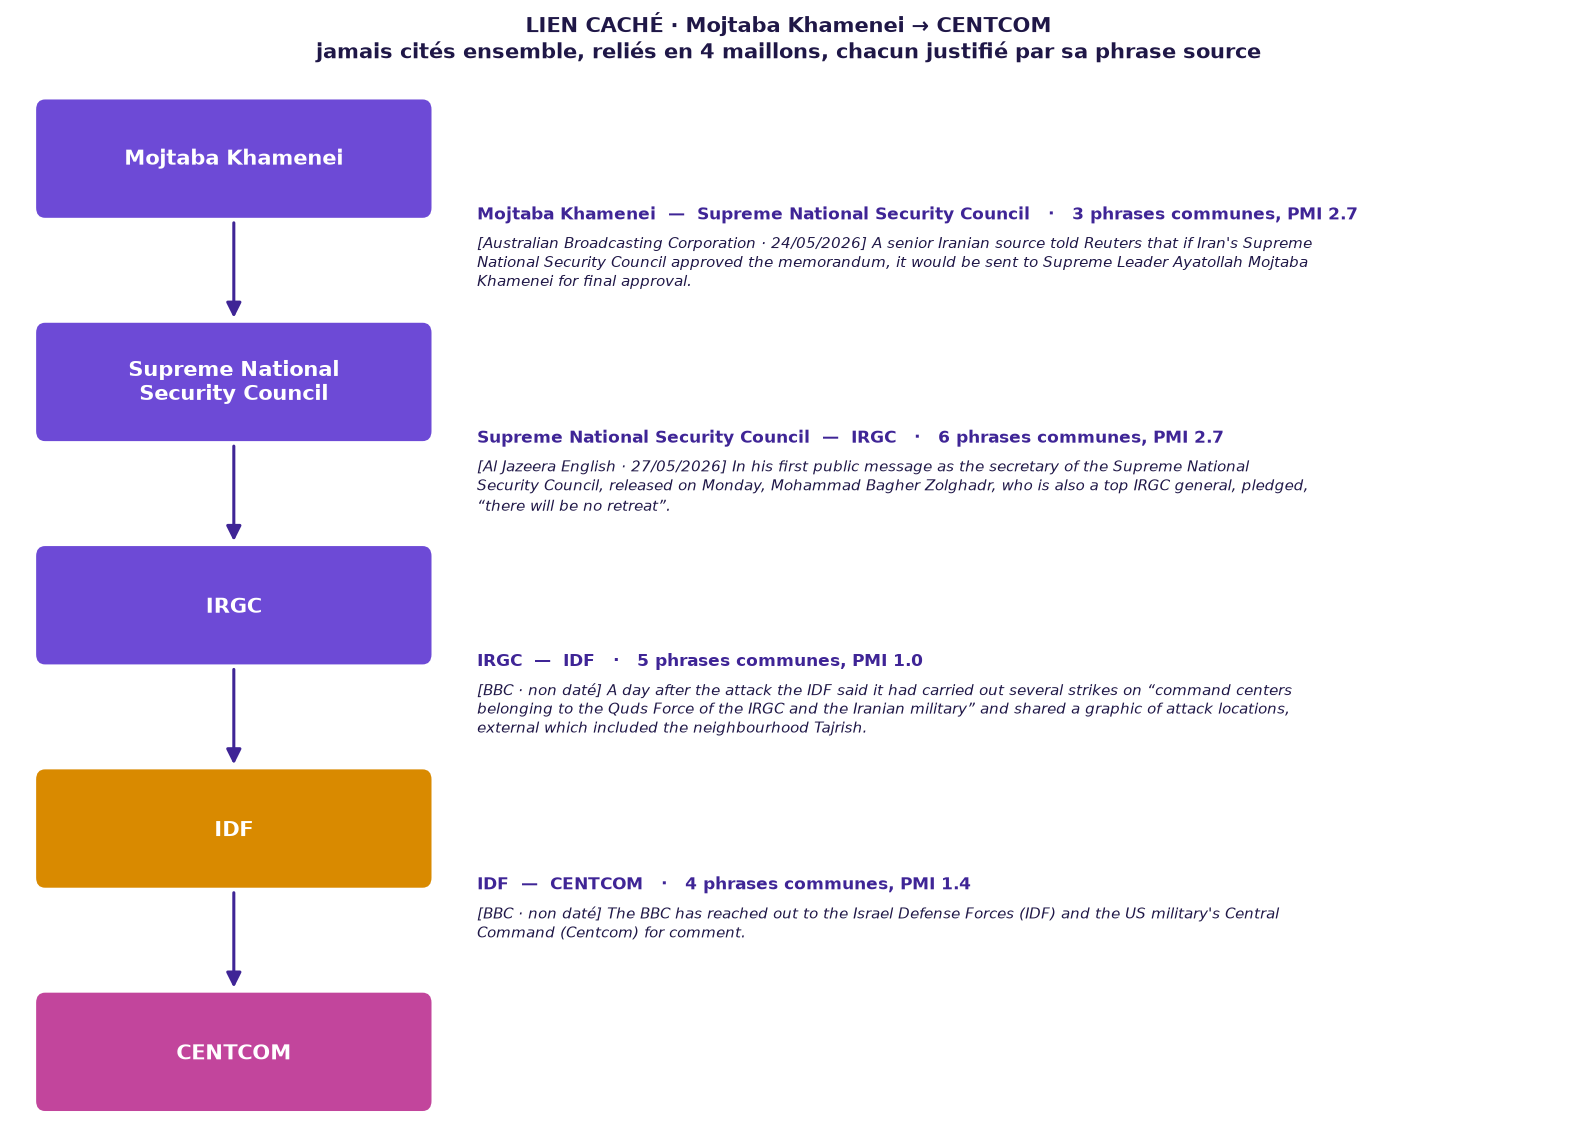

In [14]:
def figure_lien_cache(a, b, fichier):
    """Dessine la chaîne a -> b maillon par maillon, avec la preuve de chaque lien."""
    chemin = nx.shortest_path(RESEAU_ACTEURS, a, b, weight=lambda u, v, d: 1 / max(d["pmi"], 0.05))
    n = len(chemin)
    fig, ax = plt.subplots(figsize=(16, 2.3 * n))
    ax.set_xlim(0, 16)
    ax.set_ylim(-0.7, 2.0 * (n - 1) + 0.7)
    ax.axis("off")
    ax.grid(False)
    ys = [2.0 * (n - 1 - i) for i in range(n)]

    for noeud, y in zip(chemin, ys):
        couleur = COULEURS_COMM[COMM[noeud] % len(COULEURS_COMM)]
        boite(ax, 2.3, y, 4.0, 1.0, textwrap.fill(noeud, 24), couleur, couleur, "white", 15, gras=True)

    for u, v, y1, y2 in zip(chemin, chemin[1:], ys, ys[1:]):
        ax.annotate("", xy=(2.3, y2 + 0.55), xytext=(2.3, y1 - 0.55),
                    arrowprops=dict(arrowstyle="-|>", color="#3f2596", lw=2.2, mutation_scale=22))
        ym = (y1 + y2) / 2
        ax.text(4.8, ym + 0.42, f"{u}  —  {v}   ·   {T[u][v]['weight']} phrases communes, PMI {T[u][v]['pmi']:.1f}",
                fontsize=12, fontweight="bold", color="#3f2596", va="bottom")
        ax.text(4.8, ym + 0.32, textwrap.fill(preuve(u, v), 110), fontsize=10.5, color=TEXTE,
                va="top", style="italic", linespacing=1.3)

    ax.set_title(f"LIEN CACHÉ · {a} → {b}\n"
                 f"jamais cités ensemble, reliés en {n - 1} maillons, chacun justifié par sa phrase source",
                 fontsize=15, color=TEXTE, pad=16)
    plt.tight_layout()
    plt.savefig(OUTPUTS / fichier, dpi=130)
    plt.show()


if {"Mojtaba Khamenei", "CENTCOM"} <= set(RESEAU_ACTEURS):
    figure_lien_cache("Mojtaba Khamenei", "CENTCOM", "04_lien_cache.png")

## 8. Fiche acteur : l'IRGC (Gardiens de la révolution)

Le **réseau ego** d'un acteur : tout ce qui gravite autour de lui, classé par catégorie. C'est la base d'une fiche de ciblage du renseignement.

In [15]:
CIBLE = "IRGC"
voisins = pd.DataFrame([{"entité": v, "catégorie": T.nodes[v]["categorie"], "phrases": T[CIBLE][v]["weight"],
                         "spécificité (PMI)": T[CIBLE][v]["pmi"]} for v in T[CIBLE]])
fiche = (voisins[voisins["catégorie"].isin(MILITAIRE | {"PERSONNE"})].sort_values("phrases", ascending=False)
           .groupby("catégorie").head(4).sort_values(["catégorie", "phrases"], ascending=[True, False]))
print(f"{CIBLE} : {T.degree(CIBLE)} liens · sous-théâtre « {NOM_COMM[COMM[CIBLE]]} » · "
      f"intermédiarité {intermediarite[CIBLE]:.3f}")
display(fiche.style.format({"spécificité (PMI)": "{:.1f}"}).hide(axis="index"))

top_mil = fiche[fiche["catégorie"].isin(MILITAIRE)].sort_values("phrases", ascending=False).head(2)
for v in top_mil["entité"]:
    print(f"\n▌ {CIBLE} — {v}\n  {preuve(CIBLE, v)}")

IRGC : 43 liens · sous-théâtre « Donald Trump · Strait of Hormuz · IRGC » · intermédiarité 0.005


entité,catégorie,phrases,spécificité (PMI)
drone,ARMEMENT,17,0.4
ballistic missile,ARMEMENT,11,1.4
cruise missile,ARMEMENT,3,1.9
Quds Force,FORCE_ARMEE,12,3.4
Basij,FORCE_ARMEE,7,3.3
Hezbollah,FORCE_ARMEE,5,-0.7
CENTCOM,FORCE_ARMEE,5,0.1
oil tanker,NAVIRE,10,1.3
tanker,NAVIRE,3,-0.3
Donald Trump,PERSONNE,15,-1.6



▌ IRGC — Strait of Hormuz
  [CNBCTV18 · 11/06/2026] CLAIM: Iran's Islamic Revolutionary Guard Corps claims that the Strait of Hormuz is closed.



▌ IRGC — drone
  [Al Jazeera English · 27/05/2026] The Islamic Revolutionary Guard Corps (IRGC) said Iranian armed forces fired back and shot down a US-made MQ-9 Reaper drone, using a domestically-made air defence system called Arash-e Kamangir – named after a hero in Persian mythology.


## 9. Sauvegarde pour le bulletin (NB 06)

In [16]:
noeuds = pd.DataFrame([{"entite": n, "categorie": T.nodes[n]["categorie"], "articles": T.nodes[n]["articles"],
                        "communaute": NOM_COMM[COMM[n]], "intermediarite": intermediarite[n]} for n in T])
noeuds.to_csv(OUTPUTS / "graphe_noeuds.csv", index=False)
nx.to_pandas_edgelist(T, source="a", target="b").to_csv(OUTPUTS / "graphe_liens.csv", index=False)
candidats.to_csv(OUTPUTS / "liens_caches.csv", index=False)
print("graphe_noeuds.csv · graphe_liens.csv · liens_caches.csv · 04_graphe_golfe.html · 04_graphe_coeur.png · 04_graphe_arbre.png · 04_graphe_arbre.html")

graphe_noeuds.csv · graphe_liens.csv · liens_caches.csv · 04_graphe_golfe.html · 04_graphe_coeur.png · 04_graphe_arbre.png · 04_graphe_arbre.html


## Ce qu'il faut retenir

- **La co-citation dans une phrase** suffit à faire émerger, sans supervision, les sous-théâtres du conflit : le pouvoir iranien, le front naval d'Ormuz, le front Israël-Liban, le dossier nucléaire, la médiation…
- **Fréquent ≠ spécifique** : la PMI fait remonter les vraies relations de travail, là où le simple comptage ne montre que des évidences.
- **Les pivots** ne sont pas forcément les plus cités : ce sont ceux qui **relient** des groupes.
- **Chaque lien est sourcé** par la phrase d'origine. C'est indispensable pour qu'un analyste puisse s'en servir.
- **Limites, à dire en démo :**
  - une co-citation ne dit **pas la nature** du lien (alliés, ennemis, négociateurs) ;
  - le graphe reflète **ce dont parle la presse**, pas forcément la réalité du terrain ;
  - la **translittération** des noms persans et arabes (Ghalibaf / Qalibaf) éclate une personne en plusieurs nœuds si on ne la corrige pas (fait au NB 02) ;
  - typer les relations (« X attaque Y », « X négocie avec Y ») demanderait un modèle d'extraction de relations, avec GPU ou API.

> **Phrase de démo :** « Spirit Digger a transformé 2 200 articles en une carte des relations. Il y a découvert seul les sous-théâtres du conflit, identifié les acteurs qui font le pont entre eux, et mis au jour des liens indirects, chacun justifié par la phrase source. »

**Prochaine étape → NB 05 : guerre de l'information.**